In [5]:
from pathlib import Path
import signal
import time
from astropy.coordinates import SkyCoord
from astropy.io import ascii
from astropy.timeseries import LombScargle
import astropy.units as u
from astroquery.gaia import Gaia
import lightkurve as lk
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

MRT_PATH = Path("/Users/ragnar/Downloads/apjacb8b7t1_mrt.txt")
OUT_DIR = Path("/Users/ragnar/Downloads/oceanus_tess_out")
OUT_DIR.mkdir(parents=True, exist_ok=True)

GAIA_CACHE_CSV = OUT_DIR / "oceanus_members_gaia_dr3.csv"
AVAIL_CSV = OUT_DIR / "bf_tess_availability.csv"
FINAL_CSV = OUT_DIR / "bf_tess_periods.csv"


class TimeoutError(Exception):
  pass


def _alarm_handler(signum, frame):
  raise TimeoutError("Network request timed out")


def run_with_timeout(seconds, fn, *args, **kwargs):
  old_handler = signal.signal(signal.SIGALRM, _alarm_handler)
  signal.alarm(seconds)
  try:
    return fn(*args, **kwargs)
  finally:
    signal.alarm(0)
    signal.signal(signal.SIGALRM, old_handler)

In [6]:
tbl = ascii.read(MRT_PATH, format="cds")
df = tbl.to_pandas()

# Keep non-rejected Oceanus members/candidates (BF, HM, CM, LM)
members = df[df["Type"] != "R"].copy().reset_index(drop=True)

ra_deg = 15.0 * (members["RAh"] + members["RAm"] / 60.0 + members["RAs"] / 3600.0)
dec_sign = members["DE-"].map({"-": -1.0, "+": 1.0}).fillna(1.0)
dec_deg = dec_sign * (
    members["DEd"] + members["DEm"] / 60.0 + members["DEs"] / 3600.0
)
members["RA_deg"] = ra_deg
members["Dec_deg"] = dec_deg

# Turning Gaia ID into a string for search queries
gaia_num = pd.to_numeric(members["Gaia"], errors="coerce")
members["Gaia_str"] = np.where(
    gaia_num.notna() & (gaia_num > 0),
    gaia_num.fillna(0).astype("int64").astype(str),
    "",
)

print(
    f"Loaded {len(members)} non-rejected rows ({members['Type'].value_counts().to_dict()})"
)

Loaded 56 non-rejected rows ({'CM': 25, 'BF': 17, 'HM': 9, 'LM': 5})


In [7]:
valid_ids = sorted(members.loc[members["Gaia_str"] != "", "Gaia_str"])
if valid_ids:
  query = f"""
      SELECT
          source_id,
          ra AS gaia_ra,
          dec AS gaia_dec,
          parallax,
          parallax_error,
          phot_g_mean_mag,
          phot_bp_mean_mag,
          phot_rp_mean_mag,
          bp_rp,
          (phot_g_mean_mag - phot_rp_mean_mag) AS g_rp
      FROM gaiadr3.gaia_source
      WHERE source_id IN ({", ".join(valid_ids)})
      """
  job = run_with_timeout(60, Gaia.launch_job_async, query)
  gaia_df = job.get_results().to_pandas()
  gaia_df["Gaia_str"] = gaia_df["source_id"].astype(str).str.strip()
  members = members.merge(
      gaia_df, on="Gaia_str", how="left", suffixes=("_mrt", "")
  )

if "bp_rp" not in members.columns:
  members["bp_rp"] = members["phot_bp_mean_mag"] - members["phot_rp_mean_mag"]
else:
  members["bp_rp"] = members["bp_rp"].fillna(
      members["phot_bp_mean_mag"] - members["phot_rp_mean_mag"]
  )

if "g_rp" not in members.columns:
  members["g_rp"] = members["phot_g_mean_mag"] - members["phot_rp_mean_mag"]
else:
  members["g_rp"] = members["g_rp"].fillna(
      members["phot_g_mean_mag"] - members["phot_rp_mean_mag"]
  )


members[["Name", "Type", "phot_g_mean_mag", "bp_rp", "g_rp"]].dropna(
  subset=["bp_rp"]
).head(10)

members.to_csv(OUT_DIR / "oceanus_members_gaia_dr3.csv", index=False)

INFO: Query finished. [astroquery.utils.tap.core]


In [8]:
bf_df = members[members["Type"] == "BF"].reset_index(drop=True)

rows = []
for i, row in bf_df.iterrows():
  name = str(row["Name"]).strip()

  t0 = time.time()
  n_lc = 0
  status = "ok"
  try:
    if np.isfinite(row["RA_deg"]) and np.isfinite(row["Dec_deg"]):
      coord = SkyCoord(ra=row["RA_deg"] * u.deg, dec=row["Dec_deg"] * u.deg)
      sr = run_with_timeout(
          20, lk.search_lightcurve, coord, mission="TESS", radius=5 * u.arcsec
      )
    else:
      q = f"Gaia DR3 {row['Gaia_str']}" if row["Gaia_str"] else name
      sr = run_with_timeout(20, lk.search_lightcurve, q, mission="TESS")
    n_lc = len(sr)
  except Exception as e:
    status = f"err:{type(e).__name__}"

  dt = time.time() - t0
  rows.append({
      "Name": name,
      "Type": row["Type"],
      "SpType": row["SpType"],
      "Gmag": row["Gmag"],
      "phot_g_mean_mag": row.get("phot_g_mean_mag", np.nan),
      "bp_rp": row.get("bp_rp", np.nan),
      "g_rp": row.get("g_rp", np.nan),
      "Gaia_str": row["Gaia_str"],
      "RA_deg": row["RA_deg"],
      "Dec_deg": row["Dec_deg"],
      "n_lc": n_lc,
      "status": status,
  })
  pd.DataFrame(rows).to_csv(AVAIL_CSV, index=False)
  print(
      f"[{i+1}/{len(bf_df)}] {name:<24} n_lc={n_lc:<2} ({dt:.1f}s) {status}",
      flush=True,
  )

avail_df = pd.DataFrame(rows)
has_lc = avail_df[avail_df["n_lc"] > 0].reset_index(drop=True)
print(f"\nTargets with TESS light curves: {len(has_lc)}/{len(bf_df)}")

[1/17] HD 77006 A               n_lc=9  (17.4s) ok
[2/17] HD 77006 B               n_lc=9  (2.0s) ok
[3/17] TYC 3424-1000-1          n_lc=8  (6.9s) ok
[4/17] Luhman 16 A              n_lc=0  (20.0s) err:TimeoutError
[5/17] Luhman 16 B              n_lc=9  (15.5s) ok
[6/17] LSPM J1338+0744          n_lc=8  (11.2s) ok
[7/17] StKM 1-1254 A            n_lc=5  (9.5s) ok
[8/17] StKM 1-1254 B            n_lc=2  (7.0s) ok
[9/17] HD 143295 A              n_lc=0  (1.7s) ok
[10/17] HD 143295 B              n_lc=0  (1.3s) ok
[11/17] HD 143295 C              n_lc=0  (1.5s) ok
[12/17] Gaia DR3 1426873554041125120 n_lc=0  (20.0s) err:TimeoutError
[13/17] BD+18 3497 A             n_lc=20 (16.5s) ok
[14/17] BD+18 3497 B             n_lc=16 (10.8s) ok
[15/17] Gaia DR3 2123230006336124672 n_lc=0  (20.0s) err:TimeoutError
[16/17] HD 207485                n_lc=0  (20.0s) err:TimeoutError
[17/17] LP 48-485                n_lc=0  (20.0s) err:TimeoutError

Targets with TESS light curves: 9/17


In [9]:
avail_df.to_csv(OUT_DIR / "bf_tess_availability.csv", index=False)
print("Saved to:", OUT_DIR / "bf_tess_availability.csv")

has_lc.to_csv(OUT_DIR / "bf_has_tess_lc.csv", index=False)
print("Saved to:", OUT_DIR / "bf_has_tess_lc.csv")

Saved to: /Users/ragnar/Downloads/oceanus_tess_out/bf_tess_availability.csv
Saved to: /Users/ragnar/Downloads/oceanus_tess_out/bf_has_tess_lc.csv


In [10]:
retry_df = avail_df[avail_df["status"] != "ok"].copy()
print(f"Retrying {len(retry_df)} timed-out/errored targets...")

for idx, r in retry_df.iterrows():
  name = str(r["Name"]).strip()
  t0 = time.time()
  n_lc = 0
  status = "ok"
  try:
    if np.isfinite(r["RA_deg"]) and np.isfinite(r["Dec_deg"]):
      coord = SkyCoord(ra=r["RA_deg"] * u.deg, dec=r["Dec_deg"] * u.deg)
      sr = run_with_timeout(
          45, lk.search_lightcurve, coord, mission="TESS", radius=5 * u.arcsec
      )
    else:
      q = f"Gaia DR3 {r['Gaia_str']}" if r["Gaia_str"] else name
      sr = run_with_timeout(45, lk.search_lightcurve, q, mission="TESS")
    n_lc = len(sr)
  except Exception as e:
    status = f"err:{type(e).__name__}"

  dt = time.time() - t0
  avail_df.loc[idx, "n_lc"] = n_lc
  avail_df.loc[idx, "status"] = status
  print(f"  {name:<24} n_lc={n_lc:<2} ({dt:.1f}s) {status}", flush=True)

has_lc = avail_df[avail_df["n_lc"] > 0].reset_index(drop=True)
print(f"\nUpdated targets with TESS light curves: {len(has_lc)}/{len(avail_df)}")

Retrying 5 timed-out/errored targets...
  Luhman 16 A              n_lc=9  (0.6s) ok
  Gaia DR3 1426873554041125120 n_lc=45 (8.3s) ok
  Gaia DR3 2123230006336124672 n_lc=48 (8.5s) ok
  HD 207485                n_lc=54 (0.5s) ok
  LP 48-485                n_lc=40 (0.6s) ok

Updated targets with TESS light curves: 14/17


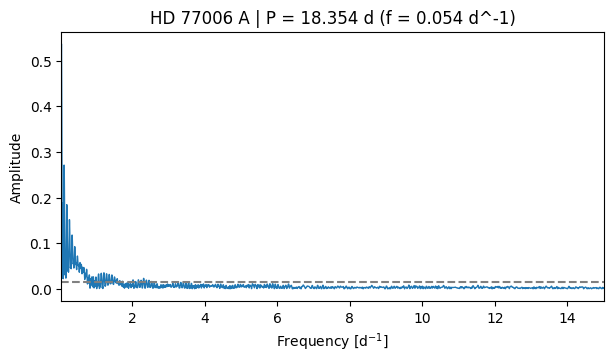

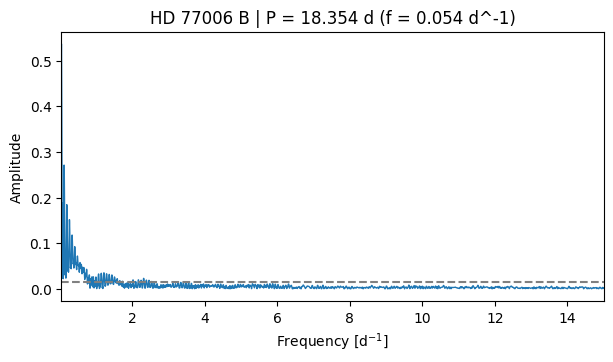

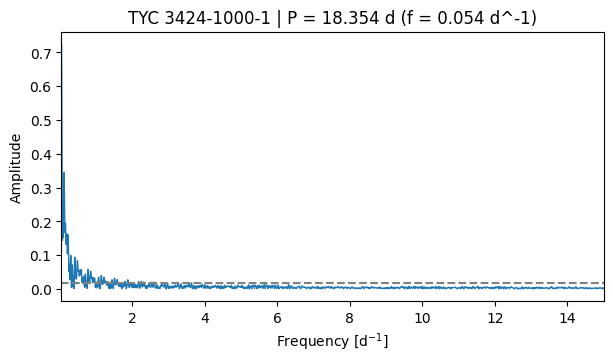

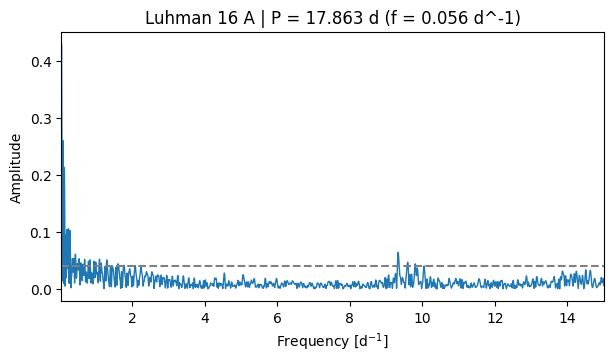

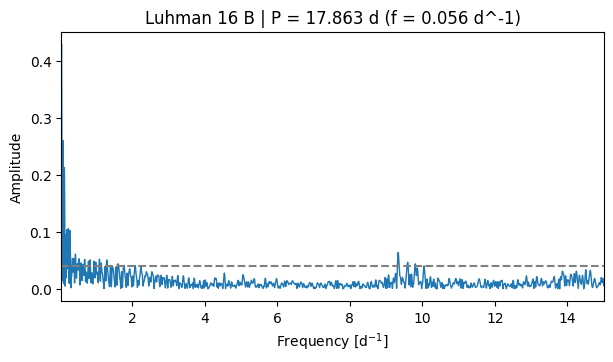

Skipping LSPM J1338+0744: LightkurveError


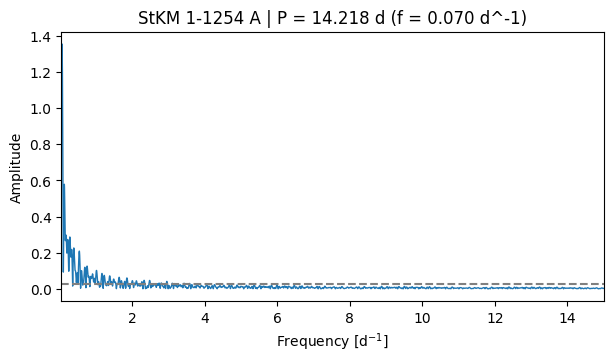

Skipping StKM 1-1254 B: LightkurveError


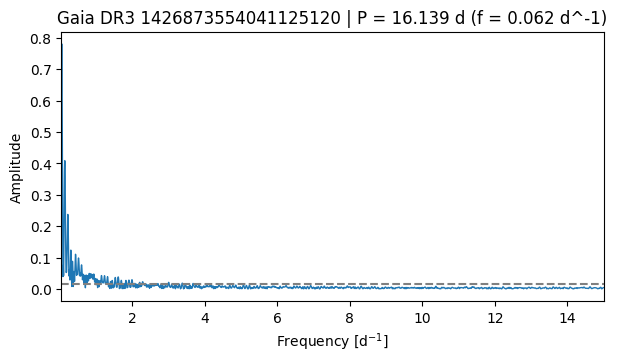

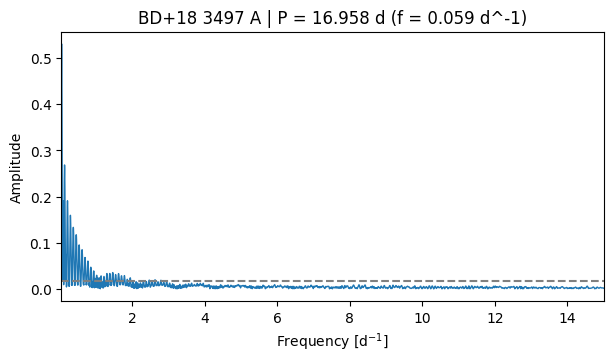

Skipping BD+18 3497 B: LightkurveError


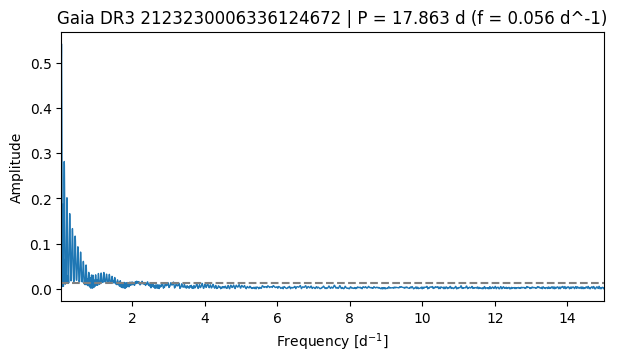

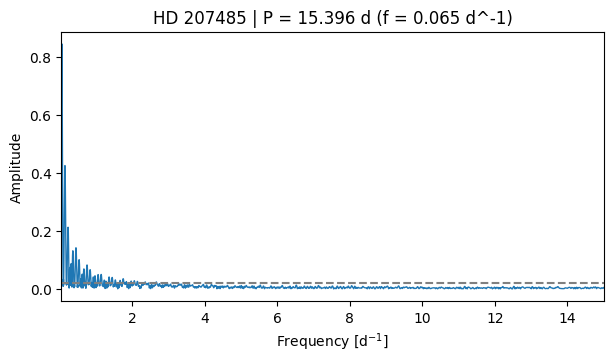

Skipping LP 48-485: LightkurveError


,Name,best_freq_d,best_period_d,amp_peak
0,HD 77006 A,0.054485,18.353524,0.536703
1,HD 77006 B,0.054485,18.353524,0.536703
2,TYC 3424-1000-1,0.054485,18.353524,0.725422
3,Luhman 16 A,0.055981,17.863332,0.429521
4,Luhman 16 B,0.055981,17.863332,0.429521
5,StKM 1-1254 A,0.070333,14.218076,1.355391
6,Gaia DR3 1426873554041125120,0.061961,16.139133,0.780545
7,BD+18 3497 A,0.058971,16.957517,0.530743
8,Gaia DR3 2123230006336124672,0.055981,17.863332,0.541938
9,HD 207485,0.064951,15.396104,0.844020


In [14]:
import astropy.units as u
from astropy.coordinates import SkyCoord
import lightkurve as lk
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.signal import lombscargle


def pgram(t, dat, title="", f_min=0.05, f_max=15.0, n_freqs=10000):
  t = np.asarray(t, dtype=float)
  dat = np.asarray(dat, dtype=float)

  mask = np.isfinite(t) & np.isfinite(dat)
  t, dat = t[mask], dat[mask]
  if len(t) < 2:
    return np.nan, np.nan, np.nan

  order = np.argsort(t)
  t = t[order] - t[order][0]
  dat = dat[order]

  dt = np.diff(t)
  dt = dt[dt > 0]
  if len(dt) == 0:
    return np.nan, np.nan, np.nan

  nyquist = 1.0 / (2.0 * np.mean(dt))
  f_lo = max(f_min, 1.0 / max(t[-1], 1e-6))
  f_hi = min(f_max, nyquist)
  if f_hi <= f_lo:
    return np.nan, np.nan, np.nan

  freqs_mesh = np.linspace(f_lo, f_hi, n_freqs)
  freqs = 2.0 * np.pi * freqs_mesh

  power = lombscargle(t, dat, freqs)
  amplitude = np.sqrt(4.0 * power / len(t))

  best_idx = int(np.argmax(amplitude))
  best_freq = float(freqs_mesh[best_idx])
  best_period_days = 1.0 / best_freq
  amp_peak = float(amplitude[best_idx])
  amp_med = float(np.median(amplitude))

  fig, ax = plt.subplots(figsize=(7, 3.5))
  ax.plot(freqs_mesh, amplitude, lw=1)
  ax.axhline(4.0 * amp_med, ls="--", color="gray")
  ax.set_title(f"{title} | P = {best_period_days:.3f} d (f = {best_freq:.3f} d^-1)")
  ax.set_xlabel("Frequency [d$^{-1}$]")
  ax.set_ylabel("Amplitude")
  ax.set_xlim(f_lo, f_hi)
  plt.show()
  plt.close(fig)

  return best_freq, best_period_days, amp_peak


results = []
for _, row in has_lc.iterrows():
  name = str(row["Name"]).strip()
  try:
    if np.isfinite(row["RA_deg"]) and np.isfinite(row["Dec_deg"]):
      coord = SkyCoord(ra=row["RA_deg"] * u.deg, dec=row["Dec_deg"] * u.deg)
      sr = lk.search_lightcurve(coord, mission="TESS", radius=5 * u.arcsec)
    else:
      sr = lk.search_lightcurve(name, mission="TESS")

    if len(sr) == 0:
      continue

    lc = sr[0].download()
    if lc is None:
      continue

    # Remove NaNs, clip extreme outliers, and flatten slow trends
    lc = lc.remove_nans().remove_outliers(sigma=5).flatten()
    best_f, best_p_d, peak_amp = pgram(
        lc.time.value, lc.flux.value, title=name, f_min=0.05, f_max=15.0
    )
    results.append({
        "Name": name,
        "best_freq_d": best_f,
        "best_period_d": best_p_d,
        "amp_peak": peak_amp,
    })
  except Exception as e:
    print(f"Skipping {name}: {type(e).__name__}")

period_df = pd.DataFrame(results)
period_df

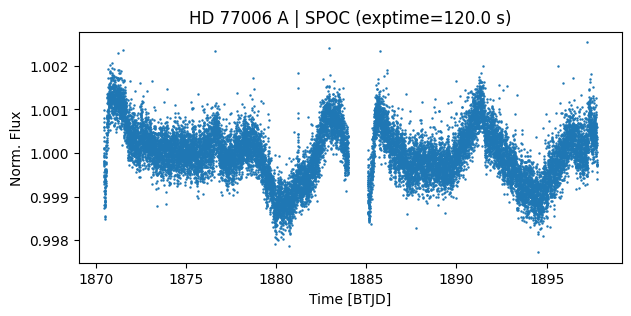

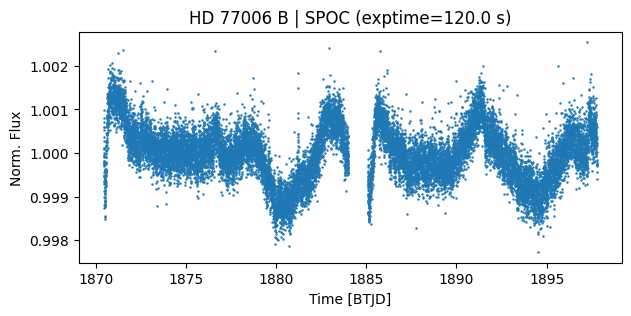

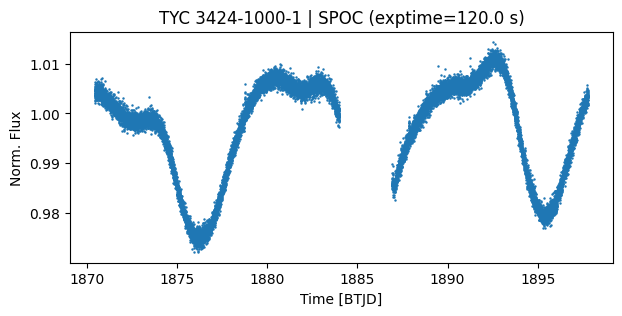

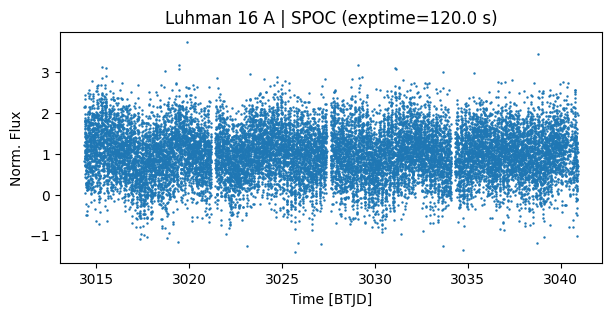

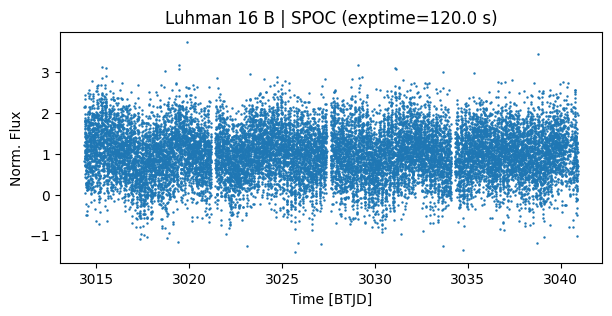

Skipping LSPM J1338+0744: LightkurveError


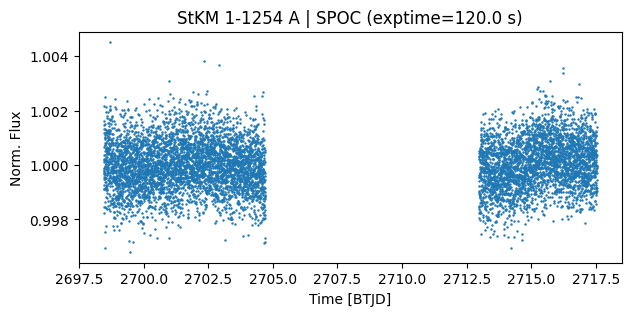

Skipping StKM 1-1254 B: LightkurveError


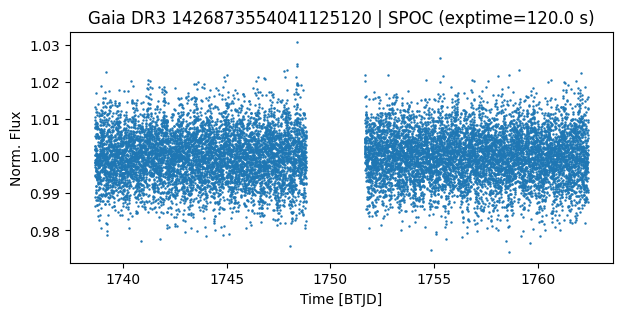

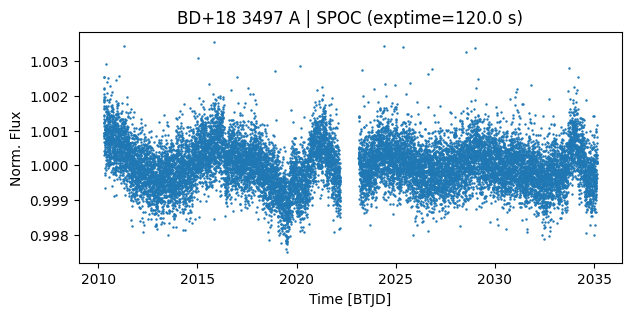

Skipping BD+18 3497 B: LightkurveError


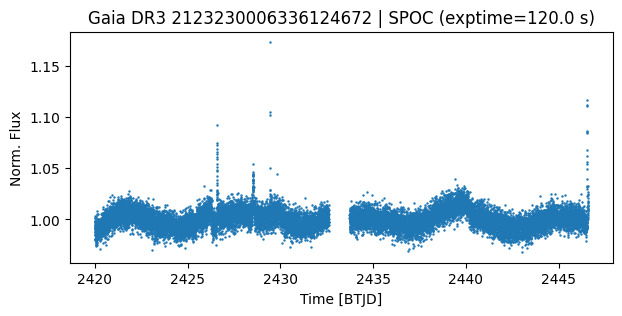

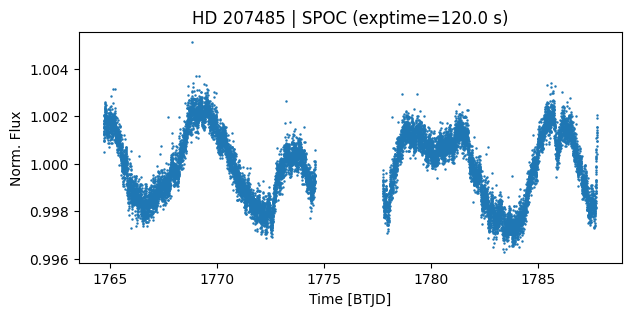

Skipping LP 48-485: LightkurveError


In [15]:
import astropy.units as u
from astropy.coordinates import SkyCoord
import lightkurve as lk
import matplotlib.pyplot as plt
import numpy as np

for _, row in has_lc.iterrows():
  name = str(row["Name"]).strip()
  try:
    if np.isfinite(row["RA_deg"]) and np.isfinite(row["Dec_deg"]):
      coord = SkyCoord(ra=row["RA_deg"] * u.deg, dec=row["Dec_deg"] * u.deg)
      sr = lk.search_lightcurve(coord, mission="TESS", radius=5 * u.arcsec)
    else:
      sr = lk.search_lightcurve(name, mission="TESS")

    if len(sr) == 0:
      continue

    lc = sr[0].download()
    if lc is None:
      continue

    lc = lc.remove_nans()
    t = lc.time.value
    flux = lc.normalize().flux.value

    fig, ax = plt.subplots(figsize=(7, 3))
    ax.plot(t, flux, ".", ms=1.5)
    ax.set_title(f"{name} | {sr[0].author[0]} (exptime={sr[0].exptime[0]})")
    ax.set_xlabel("Time [BTJD]")
    ax.set_ylabel("Norm. Flux")
    plt.show()
    plt.close(fig)

  except Exception as e:
    print(f"Skipping {name}: {type(e).__name__}")

In [12]:
periods_out = []

for idx, r in has_lc.iterrows():
  name = str(r["Name"]).strip()
  gaia_id = "" if pd.isna(r["Gaia_str"]) else str(r["Gaia_str"]).strip()
  try:
    if np.isfinite(r["RA_deg"]) and np.isfinite(r["Dec_deg"]):
      coord = SkyCoord(ra=r["RA_deg"] * u.deg, dec=r["Dec_deg"] * u.deg)
      sr = run_with_timeout(
          20, lk.search_lightcurve, coord, mission="TESS", radius=5 * u.arcsec
      )
    else:
      q = f"Gaia DR3 {gaia_id}" if gaia_id else name
      sr = run_with_timeout(20, lk.search_lightcurve, q, mission="TESS")

    lc = run_with_timeout(30, sr[0].download)
    lc = lc.remove_nans().remove_outliers(sigma=5.0).normalize()
    t = np.asarray(lc.time.value, dtype=float)
    y = np.asarray(lc.flux.value, dtype=float) - 1.0
    m = np.isfinite(t) & np.isfinite(y)
    t, y = t[m], y[m]

    periods = np.linspace(0.1, 20.0, 8000)
    power = LombScargle(t, y).power(1.0 / periods)
    best_i = int(np.argmax(power))
    p_best = float(periods[best_i])
    p_pow = float(power[best_i])

    fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
    axes[0].plot(t, y, ".", ms=1.0)
    axes[0].set(
        title=f"{name} (n_lc={r['n_lc']})",
        xlabel="BTJD",
        ylabel="Norm Flux - 1",
    )

    axes[1].plot(periods, power, lw=0.8)
    axes[1].axvline(p_best, color="r", ls="--", lw=1)
    axes[1].set(
        title=f"Best P = {p_best:.4f} d (pow={p_pow:.3f})",
        xlabel="Period (d)",
        ylabel="LS Power",
    )

    plt.tight_layout()
    plt.savefig(OUT_DIR / f"{name.replace(' ', '_')}_ls.png", dpi=130)
    plt.close(fig)

    periods_out.append({
        "Name": name,
        "SpType": r["SpType"],
        "Gmag": r["Gmag"],
        "phot_g_mean_mag": r["phot_g_mean_mag"],
        "bp_rp": r["bp_rp"],
        "g_rp": r["g_rp"],
        "Gaia_str": gaia_id,
        "n_lc": r["n_lc"],
        "best_period_d": p_best,
        "ls_power": p_pow,
    })
    print(
        f"  -> {name:<24} P = {p_best:.4f} d | pow = {p_pow:.3f} | "
        f"bp_rp = {r['bp_rp']} | g_rp = {r['g_rp']}",
        flush=True,
    )
  except Exception as e:
    print(f"  -> {name:<24} FAILED: {e}", flush=True)

final_df = pd.DataFrame(periods_out)
final_df.to_csv(FINAL_CSV, index=False)
print(f"\nSaved final results to {FINAL_CSV}")
final_df

  -> HD 77006 A               P = 6.7027 d | pow = 0.319 | bp_rp = nan | g_rp = nan
  -> HD 77006 B               P = 6.7027 d | pow = 0.319 | bp_rp = nan | g_rp = nan
  -> TYC 3424-1000-1          P = 9.8721 d | pow = 0.746 | bp_rp = nan | g_rp = nan
  -> Luhman 16 A              FAILED: index 0 out of range for table with length 0


/Users/ragnar/Library/Python/3.9/lib/python/site-packages/lightkurve/lightcurve.py:1261: LightkurveWarning: The light curve appears to be zero-centered (median=1.32e+00 electron / s +/- 6.14e+00 electron / s); `normalize()` will divide the light curve by a value close to zero, which is probably not what you want.
  warnings.warn(


  -> Luhman 16 B              P = 0.8513 d | pow = 0.001 | bp_rp = nan | g_rp = nan
  -> LSPM J1338+0744          FAILED: index 0 out of range for table with length 0


  -> StKM 1-1254 A            P = 4.6527 d | pow = 0.041 | bp_rp = nan | g_rp = nan
  -> StKM 1-1254 B            FAILED: index 0 out of range for table with length 0
  -> Gaia DR3 1426873554041125120 FAILED: Network request timed out
  -> BD+18 3497 B             FAILED: Error in reading Data product /Users/ragnar/.lightkurve/cache/mastDownload/HLSP/hlsp_tars_tess_ffi_s0026-0000000275218861_tess/hlsp_tars_tess_ffi_s0026-0000000275218861_tess_v01_lc.fits of type generic .
This file may be corrupt due to an interrupted download. Please remove it from your disk and try again.

Saved final results to /Users/ragnar/Downloads/oceanus_tess_out/bf_tess_periods.csv


,Name,SpType,Gmag,phot_g_mean_mag,bp_rp,g_rp,Gaia_str,n_lc,best_period_d,ls_power
0,HD 77006 A,G5,7.802,NaN,NaN,NaN,1015799283499485440,9,6.702650,0.318576
1,HD 77006 B,(M3),12.299,NaN,NaN,NaN,1015799283498356224,9,6.702650,0.318576
2,TYC 3424-1000-1,(K4),10.462,NaN,NaN,NaN,1011277541930006784,8,9.872122,0.745712
3,Luhman 16 B,T0.5,16.962,NaN,NaN,NaN,,9,0.851319,0.000950
4,StKM 1-1254 A,K4/5,10.478,NaN,NaN,NaN,1193907316656812800,5,4.652694,0.041161


In [13]:
from pathlib import Path
import shutil
import numpy as np
import pandas as pd

# 1. Backfill Gaia colors & Gmag from `members` into `final_df`
gaia_lookup = members[["Name", "Gaia_str", "phot_g_mean_mag", "bp_rp", "g_rp"]].copy()
gaia_lookup["Name"] = gaia_lookup["Name"].astype(str).str.strip()

final_df = pd.read_csv(FINAL_CSV, dtype={"Gaia_str": str})
final_df["Name"] = final_df["Name"].astype(str).str.strip()
final_df = final_df.drop(
    columns=[c for c in ["phot_g_mean_mag", "bp_rp", "g_rp"] if c in final_df.columns]
).merge(gaia_lookup, on="Name", how="left", suffixes=("", "_gaia"))

final_df.to_csv(FINAL_CSV, index=False)
print("Updated Gaia colors in:", FINAL_CSV)
print(final_df[["Name", "best_period_d", "ls_power", "phot_g_mean_mag", "bp_rp", "g_rp"]])

# 2. Clear corrupt HLSP cache entry for BD+18 3497 B if present
corrupt_dir = Path("/Users/ragnar/.lightkurve/cache/mastDownload/HLSP")
if corrupt_dir.exists():
  for p in corrupt_dir.rglob("*s0026*275218861*"):
    print("Removing corrupt cached file:", p)
    p.unlink(missing_ok=True)

Updated Gaia colors in: /Users/ragnar/Downloads/oceanus_tess_out/bf_tess_periods.csv
              Name  best_period_d  ls_power  phot_g_mean_mag     bp_rp  \
0       HD 77006 A       6.702650  0.318576         7.801909  0.786602   
1       HD 77006 B       6.702650  0.318576        12.298767       NaN   
2  TYC 3424-1000-1       9.872122  0.745712        10.461653  1.403324   
3      Luhman 16 B       0.851319  0.000950              NaN       NaN   
4    StKM 1-1254 A       4.652694  0.041161        10.477854  1.607769   

       g_rp  
0  0.493335  
1       NaN  
2  0.764103  
3       NaN  
4  0.845273  
Removing corrupt cached file: /Users/ragnar/.lightkurve/cache/mastDownload/HLSP/hlsp_tars_tess_ffi_s0026-0000000275218861_tess


PermissionError: [Errno 1] Operation not permitted: '/Users/ragnar/.lightkurve/cache/mastDownload/HLSP/hlsp_tars_tess_ffi_s0026-0000000275218861_tess'

In [14]:
from astropy.io import ascii
import pandas as pd

path = "/Users/ragnar/Downloads/apjacb8b7t1_mrt.txt"
tbl = ascii.read(path, format="cds")
df = tbl.to_pandas()

print("Total rows parsed:", len(df))
print("Columns:", list(df.columns))
print("\nCounts by Type:")
print(df["Type"].value_counts(dropna=False))

print("\nFirst 5 rows:")
print(df[["Name", "Gaia", "Type", "SpType", "Gmag"]].head(5).to_string())

print("\nLast 5 rows:")
print(df[["Name", "Gaia", "Type", "SpType", "Gmag"]].tail(5).to_string())

Total rows parsed: 89
Columns: ['Name', 'f_Name', 'Gaia', 'Type', 'Origin', 'SpType', 'RAh', 'RAm', 'RAs', 'DE-', 'DEd', 'DEm', 'DEs', 'Gmag', 'W1mag', 'Youth', 'DeltaUW', 'Obs', 'Mem', 'Rej', 'Ref']

Counts by Type:
Type
R     33
CM    25
BF    17
HM     9
LM     5
Name: count, dtype: int64

First 5 rows:
              Name                 Gaia Type SpType    Gmag
0       HD 77006 A  1015799283499485440   BF     G5   7.802
1       HD 77006 B  1015799283498356224   BF   (M3)  12.299
2  TYC 3424-1000-1  1011277541930006784   BF   (K4)  10.462
3      Luhman 16 A  5353626573555863552   BF   L7.5  16.945
4      Luhman 16 B                 <NA>   BF   T0.5  16.962

Last 5 rows:
                            Name                 Gaia Type  SpType    Gmag
84  Gaia DR3 4514591346333008640  4514591346333008896    R    (M9)  19.942
85  Gaia DR3 4514524757179567744  4514524757179567616    R    (M9)  19.941
86  Gaia DR3 4314500777213121152  4314500777213121024    R  (M5::)  20.372
87  Gaia DR3 42961